In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
# Importar datos
dSegment = pd.read_excel("DIM_SEGMENT.xlsx")
dProduct = pd.read_excel("DIM_PRODUCT.xlsx")
dCalendar = pd.read_excel("DIM_CALENDAR.xlsx")
dCategory = pd.read_csv("DIM_CATEGORY.csv")
dSales = pd.read_csv("FACT_SALES.csv")
dfs = [dSegment, dProduct, dCalendar, dCategory, dSales]

In [3]:
# Descriptores básicos
for i in dfs:
    i.info()
    print(i.shape)
    print(i.describe())

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   CATEGORY  53 non-null     int64
 1   ATTR1     53 non-null     str  
 2   ATTR2     53 non-null     str  
 3   ATTR3     52 non-null     str  
 4   FORMAT    53 non-null     str  
 5   SEGMENT   53 non-null     str  
dtypes: int64(1), str(5)
memory usage: 4.9 KB
(53, 6)
       CATEGORY
count      53.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   MANUFACTURER      505 non-null    str  
 1   BRAND             505 non-null    str  
 2   ITEM              503 non-null    str  
 3   ITEM_DESCRIPTION  505 non-null    str  
 4   CATEGORY          505 non-null    int64
 5   FO

In [4]:
#Borrar duplicados:
for i in range(len(dfs)):
    dfs[i] = dfs[i].drop_duplicates()

for i in dfs:
    i.info()
    print(i.shape)
    print(i.describe())

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   CATEGORY  53 non-null     int64
 1   ATTR1     53 non-null     str  
 2   ATTR2     53 non-null     str  
 3   ATTR3     52 non-null     str  
 4   FORMAT    53 non-null     str  
 5   SEGMENT   53 non-null     str  
dtypes: int64(1), str(5)
memory usage: 4.9 KB
(53, 6)
       CATEGORY
count      53.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   MANUFACTURER      505 non-null    str  
 1   BRAND             505 non-null    str  
 2   ITEM              503 non-null    str  
 3   ITEM_DESCRIPTION  505 non-null    str  
 4   CATEGORY          505 non-null    int64
 5   FO

In [5]:
#Borrar registros NaN de la columna Attr1 e ITEM de Product
dProduct = dProduct.dropna(subset = ["ATTR1"])
dProduct = dProduct.dropna(subset = ["ITEM"])
dProduct.info()

<class 'pandas.DataFrame'>
Index: 497 entries, 0 to 504
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   MANUFACTURER      497 non-null    str  
 1   BRAND             497 non-null    str  
 2   ITEM              497 non-null    str  
 3   ITEM_DESCRIPTION  497 non-null    str  
 4   CATEGORY          497 non-null    int64
 5   FORMAT            497 non-null    str  
 6   ATTR1             497 non-null    str  
 7   ATTR2             497 non-null    str  
 8   ATTR3             497 non-null    str  
dtypes: int64(1), str(8)
memory usage: 101.2 KB


In [6]:
#Hacer que todos los ITEM en dProduct y ITEM_CODE en dSales tengan una cadena de 16 caracteres
dProduct["ITEM"] = dProduct["ITEM"].astype(str).str.zfill(16)
dProduct
dSales["ITEM_CODE"] = dSales["ITEM_CODE"].astype(str).str.zfill(16)
dSales

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,0007501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,0007702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,0007501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,0007501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5
...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO
121998,26-23,0007501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO
121999,26-23,0007501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO


In [7]:
# Traer columna DATE de dCalendar a dSaleFinal y borrar WEEK
dSalesFinal = pd.merge(
    dSales,
    dCalendar[["WEEK", "DATE"]],
    on = "WEEK",
    how = "inner"
)
dSalesFinal.drop(columns = ["WEEK"], inplace = True)
dSalesFinal

,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,DATE
0,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,2022-08-28
1,0007501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,2022-08-28
2,0007702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,2022-08-28
3,0007501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,2022-08-28
4,0007501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,2022-08-28
...,...,...,...,...,...,...
121997,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,2023-07-03
121998,0007501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,2023-07-03
121999,0007501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,2023-07-03
122000,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,2023-07-03


In [8]:
# Traer información del producto a dSales Final
dSalesFinal = pd.merge(
    dSalesFinal,
    dProduct[["ITEM", "ITEM_DESCRIPTION", "CATEGORY", "FORMAT", "ATTR1", "ATTR2", "ATTR3"]],
    left_on = "ITEM_CODE",
    right_on = "ITEM",
    how = "inner"
)

dSalesFinal.drop(columns = ["ITEM"], inplace = True)
dSalesFinal

,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,DATE,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,2022-08-28,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
1,0007501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
2,0007702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
3,0007501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
4,0007501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,2022-08-28,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
...,...,...,...,...,...,...,...,...,...,...,...,...
121997,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
121998,0007501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,1,LIQUIDO,PRELAVADOR,FABRIC TREATMENT,ROSA
121999,0007501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 DOYPACK 120 GR 7501058753441,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
122000,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA


In [17]:
#Traer nombre de la CATEGORIA a dSalesFinal
# Unir las tablas mediante el nombre de la categoría
dSalesFinal = pd.merge(
    dSalesFinal,
    dCategory[["ID_CATEGORY", "CATEGORY"]],
    on="CATEGORY",
    how="inner"
)

# Sustituir el nombre de la categoría
dSalesFinal["CATEGORY"] = dSalesFinal["CATEGORY"].replace({
    "FABRIC TREATMENT and SANIT\r\n": "FABRIC TREATMENT and SANITIZER"
})

# Mostrar resultado
dSalesFinal


,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,DATE,ITEM_DESCRIPTION,FORMAT,ATTR1,ATTR2,ATTR3,CATEGORY,ID_CATEGORY
0,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,2022-08-28,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
1,0007501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
2,0007702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
3,0007501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
4,0007501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,2022-08-28,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
121998,0007501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,LIQUIDO,PRELAVADOR,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
121999,0007501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 DOYPACK 120 GR 7501058753441,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1
122000,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1


In [18]:
#Traer Segmento a dFinalSales
dSalesFinal = pd.merge(
    dSalesFinal,
    dSegment[["FORMAT", "ATTR1", "ATTR2", "ATTR3", "SEGMENT"]],
    left_on = ["FORMAT", "ATTR1", "ATTR2", "ATTR3"],
    right_on = ["FORMAT", "ATTR1", "ATTR2", "ATTR3"]
)
dSalesFinal

,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,DATE,ITEM_DESCRIPTION,FORMAT,ATTR1,ATTR2,ATTR3,CATEGORY,ID_CATEGORY,SEGMENT
0,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,2022-08-28,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
1,0007501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
2,0007702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
3,0007501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,2022-08-28,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
4,0007501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,2022-08-28,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
121998,0007501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,LIQUIDO,PRELAVADOR,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,PRETREAT
121999,0007501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER O2 DOYPACK 120 GR 7501058753441,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER
122000,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,2023-07-03,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANITIZER,1,POWDER


In [19]:
#Acomodar columnas
dSalesFinal = dSalesFinal[
    ["DATE", "TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES", "ITEM_CODE", "ITEM_DESCRIPTION","FORMAT",
    "TOTAL_UNIT_AVG_WEEKLY_SALES", "REGION", "SEGMENT", "CATEGORY", "ATTR1", "ATTR2", "ATTR3"]  
]
dSalesFinal

,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,SEGMENT,CATEGORY,ATTR1,ATTR2,ATTR3
0,2022-08-28,0.006,0.139,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,1.000,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
1,2022-08-28,0.487,116.519,0007501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,2.916,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
2,2022-08-28,1.391,68.453,0007702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,POLVO,5.171,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
3,2022-08-28,0.022,1.481,0007501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,1.833,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
4,2022-08-28,2.037,182.839,0007501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,5.375,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,2023-07-03,1.192,150.829,7501058792778BP1,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,POLVO,4.000,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
121998,2023-07-03,1.947,235.416,0007501058757630,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,LIQUIDO,2.797,TOTAL AUTOS SCANNING MEXICO,PRETREAT,FABRIC TREATMENT and SANITIZER,PRELAVADOR,FABRIC TREATMENT,ROSA
121999,2023-07-03,18.013,429.289,0007501058753441,VANISH PODER O2 DOYPACK 120 GR 7501058753441,POLVO,9.102,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA
122000,2023-07-03,21.152,210.276,7702626204208BP1,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,POLVO,22.172,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA


In [24]:
#Traer el mes y año de la fecha de la venta
dSalesFinal2 = dSalesFinal.copy()
dSalesFinal2['YEAR'] = dSalesFinal2['DATE'].dt.year
dSalesFinal2['MONTH'] = dSalesFinal2['DATE'].dt.month
dSalesFinal2

,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,SEGMENT,CATEGORY,ATTR1,ATTR2,ATTR3,YEAR,MONTH
0,2022-08-28,0.006,0.139,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,1.000,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
1,2022-08-28,0.487,116.519,0007501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,2.916,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
2,2022-08-28,1.391,68.453,0007702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,POLVO,5.171,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
3,2022-08-28,0.022,1.481,0007501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,1.833,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
4,2022-08-28,2.037,182.839,0007501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,5.375,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,2023-07-03,1.192,150.829,7501058792778BP1,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,POLVO,4.000,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2023,7
121998,2023-07-03,1.947,235.416,0007501058757630,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,LIQUIDO,2.797,TOTAL AUTOS SCANNING MEXICO,PRETREAT,FABRIC TREATMENT and SANITIZER,PRELAVADOR,FABRIC TREATMENT,ROSA,2023,7
121999,2023-07-03,18.013,429.289,0007501058753441,VANISH PODER O2 DOYPACK 120 GR 7501058753441,POLVO,9.102,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2023,7
122000,2023-07-03,21.152,210.276,7702626204208BP1,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,POLVO,22.172,TOTAL AUTOS SCANNING MEXICO,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2023,7


In [176]:
#Quitar REGION 'TOTAL AUTOS SCANNING MEXICO'

dSalesFinal3 = dSalesFinal2.copy()
dSalesFinal3 = dSalesFinal3.drop(
    dSalesFinal3[dSalesFinal3['REGION'] == 'TOTAL AUTOS SCANNING MEXICO'].index
    )

#Descritores

dSalesFinal3.describe()

,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,YEAR,MONTH
count,101012,101012.000000,101012.000000,101012.000000,101012.000000,101012.000000
mean,2022-10-05 22:20:57.070447,1.939177,54.661135,9.938591,2022.346236,5.530303
min,2022-01-09 00:00:00,0.000000,0.001000,0.042000,2022.000000,1.000000
25%,2022-05-15 00:00:00,0.056000,2.406000,2.297750,2022.000000,3.000000
50%,2022-10-02 00:00:00,0.298000,14.062000,3.962000,2022.000000,5.000000
75%,2023-02-27 00:00:00,1.132000,49.441500,8.677000,2023.000000,8.000000
max,2023-07-17 00:00:00,143.003000,3307.388000,794.000000,2023.000000,12.000000
std,NaN,6.445394,150.263682,22.428377,0.475772,3.212742


In [204]:
#Datos únicos por variable
groups = {}

for i in dSalesFinal3.columns:
    valor = dSalesFinal3.groupby(i).ngroups
    groups[i] = valor

groups

{'DATE': 80,
 'TOTAL_UNIT_SALES': 11364,
 'TOTAL_VALUE_SALES': 52974,
 'ITEM_CODE': 350,
 'ITEM_DESCRIPTION': 350,
 'FORMAT': 5,
 'TOTAL_UNIT_AVG_WEEKLY_SALES': 23967,
 'REGION': 6,
 'SEGMENT': 7,
 'CATEGORY': 1,
 'ATTR1': 4,
 'ATTR2': 3,
 'ATTR3': 8,
 'YEAR': 2,
 'MONTH': 12}

In [212]:
#Comparación por tiempo
eta1 = dSalesFinal3.groupby(['YEAR', 'MONTH'])[['TOTAL_UNIT_SALES','TOTAL_VALUE_SALES']].sum().reset_index()
eta1 = eta1.sort_values(by = 'TOTAL_VALUE_SALES', ascending = False)

eta1.tail(10)

,YEAR,MONTH,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
15,2023,4,9077.081,273164.845
7,2022,8,10168.606,272720.568
14,2023,3,9068.317,270574.960
10,2022,11,9153.856,263025.091
13,2023,2,8772.530,261785.785
3,2022,4,9413.444,261002.160
11,2022,12,8909.558,260553.095
2,2022,3,9353.924,255026.221
1,2022,2,9462.343,247267.666
18,2023,7,8047.383,236563.339


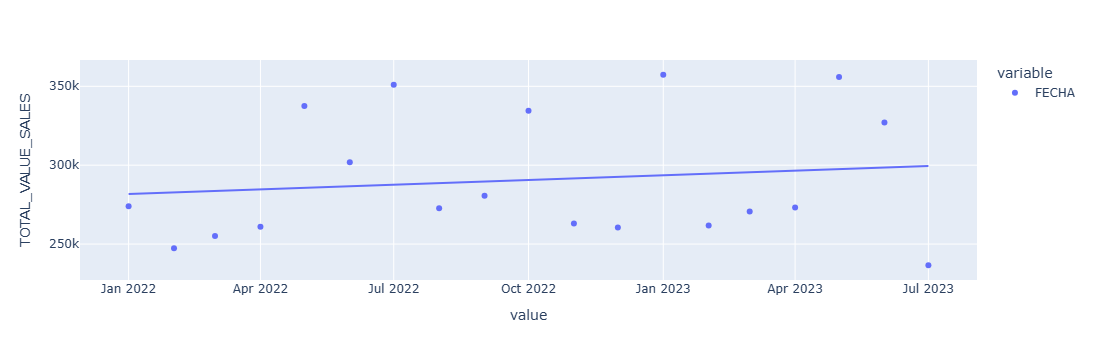

In [177]:
eta1['FECHA'] = pd.to_datetime(
    eta1['YEAR'].astype(str) + '-' +
    eta1['MONTH'].astype(str) + '-01'
)

eta1 = eta1.sort_values(by = 'FECHA', ascending = True)

#Tendencia por tiempo
px.scatter(
    eta1,
    x = ['FECHA'],
    y = 'TOTAL_VALUE_SALES',
    trendline = 'ols'
)

In [223]:
#Ventas por Region

eta2 = dSalesFinal3.groupby('REGION')[['TOTAL_VALUE_SALES']].sum().reset_index()
eta2 = eta2.sort_values(
    by = 'TOTAL_VALUE_SALES',
    ascending = False
)
eta2

,REGION,TOTAL_VALUE_SALES
1,TOTAL AUTOS AREA 2,1188796.150
4,TOTAL AUTOS AREA 5,1153335.538
5,TOTAL AUTOS AREA 6,983957.571
2,TOTAL AUTOS AREA 3,803655.337
0,TOTAL AUTOS AREA 1,714249.979
3,TOTAL AUTOS AREA 4,677435.998


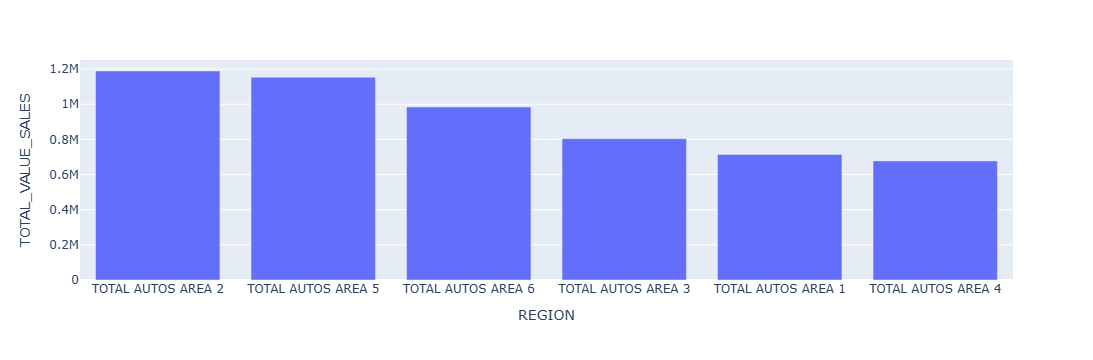

In [179]:
px.bar(
    eta2,
    x = 'REGION',
    y = 'TOTAL_VALUE_SALES'
)

In [174]:
dSalesFinal3

,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,SEGMENT,CATEGORY,ATTR1,ATTR2,ATTR3,YEAR,MONTH
0,2022-08-28,0.006,0.139,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,1.000,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
1,2022-08-28,0.487,116.519,0007501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,2.916,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
2,2022-08-28,1.391,68.453,0007702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,POLVO,5.171,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
3,2022-08-28,0.022,1.481,0007501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,1.833,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
4,2022-08-28,2.037,182.839,0007501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,5.375,TOTAL AUTOS AREA 5,POWDER,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121929,2023-06-05,0.009,1.355,0007501058717276,LYSOL SANITIZANTE DE ROPA SPORT BOTELLA 1.21 L...,LIQUIDO,1.000,TOTAL AUTOS AREA 6,SANITIZER,FABRIC TREATMENT and SANITIZER,SANITIZANTE,SANITIZANTE,SANITIZANTE,2023,6
121930,2023-06-05,0.144,23.471,0007501058795908,LYSOL CRISP LINEN SANITIZANTE DE ROPA BOT 2.66...,LIQUIDO,2.087,TOTAL AUTOS AREA 6,SANITIZER,FABRIC TREATMENT and SANITIZER,SANITIZANTE,SANITIZANTE,SANITIZANTE,2023,6
121931,2023-06-05,0.103,5.964,0007501058717252,LYSOL SANITIZANTE DE ROPA CRISP LINEN SCENT PO...,LIQUIDO,1.814,TOTAL AUTOS AREA 6,SANITIZER,FABRIC TREATMENT and SANITIZER,SANITIZANTE,SANITIZANTE,SANITIZANTE,2023,6
121932,2023-06-05,0.454,71.162,0007501058716798,VANISH CRYSTAL WHITE QUITAMANCHAS GEL BOT 3.8 ...,GEL,3.223,TOTAL AUTOS AREA 6,LIQUID & GEL,FABRIC TREATMENT and SANITIZER,SAFE BLEACH,FABRIC TREATMENT,BLANCO,2023,6


In [235]:
#Boxplot

def boxplot(fila, variable):
    fig = px.box(
    dSalesFinal3,
    y = fila,
    title = (f'Boxplot de {fila}'),
    color = variable
)
    fig.write_image(f'boxplot_{fila}_{variable}.jpg')
    return fig

In [183]:
#Gráficos de ventas por variable

def VentasX(elemento):
    eta5 = dSalesFinal3.groupby(['YEAR', 'MONTH', elemento])[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].sum().reset_index()
    eta5['FECHA'] = pd.to_datetime(
        eta5['YEAR'].astype(str) + '-' +
        eta5['MONTH'].astype(str) + '-01'
    )
    
    fig = px.line(
        eta5,
        x = 'FECHA',
        y = 'TOTAL_VALUE_SALES',
        color = elemento,
        markers = True
    )
    
    fig.write_image(f'{elemento}_{fila}_{variable}.jpg')
    
    fig.show()

In [201]:
#Crecimiento en el periodo
def Growth(elemento):
    eta5 = dSalesFinal3.groupby(['YEAR', 'MONTH', elemento])[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].sum().reset_index()
    eta5['FECHA'] = pd.to_datetime(
        eta5['YEAR'].astype(str) + '-' +
        eta5['MONTH'].astype(str) + '-01'
    )
    
    eta5 = eta5.pivot_table(
        values='TOTAL_VALUE_SALES',
        index=elemento,
        columns='FECHA',
        aggfunc='sum'
    ).reset_index()

    eta5['GROWTH'] = (
        (eta5[pd.Timestamp('2023-07-01')] -
         eta5[pd.Timestamp('2022-01-01')]) /
         eta5[pd.Timestamp('2022-01-01')]
    ) * 100

    eta5 = eta5.sort_values(by='GROWTH', ascending=False)
    
    return eta5

In [196]:
#Gráfica del crecimiento en el periodo

def GrowthGraf(elemento):

    from plotly.subplots import make_subplots
    import plotly.graph_objects as go

    eta5 = dSalesFinal3.groupby(['YEAR', 'MONTH', elemento])[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].sum().reset_index()
    eta5['FECHA'] = pd.to_datetime(
        eta5['YEAR'].astype(str) + '-' +
        eta5['MONTH'].astype(str) + '-01'
    )
    
    eta5 = eta5.pivot_table(
        values='TOTAL_VALUE_SALES',
        index=elemento,
        columns='FECHA',
        aggfunc='sum'
    ).reset_index()

    eta5['GROWTH'] = (
        (eta5[pd.Timestamp('2023-07-01')] -
         eta5[pd.Timestamp('2022-01-01')]) /
         eta5[pd.Timestamp('2022-01-01')]
    ) * 100

    eta5 = eta5.sort_values(by='GROWTH', ascending=False)

    fig = make_subplots(specs=[[{"secondary_y": True}]])

    # Barras de ventas 2023
    fig.add_trace(
        go.Bar(
            x=eta5[elemento],
            y=eta5[pd.Timestamp('2023-07-01')],
            name='2023-07',
            opacity=0.5
        ),
        secondary_y=False
    )

    # Barras de ventas 2022
    fig.add_trace(
        go.Bar(
            x=eta5[elemento],
            y=eta5[pd.Timestamp('2022-01-01')],
            name='2022-01',
            opacity=0.5
        ),
        secondary_y=False
    )

    # Línea de crecimiento porcentual
    fig.add_trace(
        go.Scatter(
            x=eta5[elemento],
            y=eta5['GROWTH'],
            name='GROWTH (%)',
            mode='lines+markers'
        ),
        secondary_y=True
    )

    fig.update_layout(
        title=f'Ventas y crecimiento por {elemento}',
        barmode='group',
        xaxis_title=elemento
    )

    fig.update_yaxes(title_text='Ventas globales', secondary_y=False)
    fig.update_yaxes(title_text='Crecimiento (%)', secondary_y=True)

    fig.show()

In [216]:
#Boxplot del crecimiento durante el periodo
def OutGrowth(elemento):

    eta5 = dSalesFinal3.groupby(['YEAR', 'MONTH', elemento])[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].sum().reset_index()
    eta5['FECHA'] = pd.to_datetime(
        eta5['YEAR'].astype(str) + '-' +
        eta5['MONTH'].astype(str) + '-01'
    )
    
    eta5 = eta5.pivot_table(
        values='TOTAL_VALUE_SALES',
        index=elemento,
        columns='FECHA',
        aggfunc='sum'
    ).reset_index()

    eta5['GROWTH'] = (
        (eta5[pd.Timestamp('2023-07-01')] -
         eta5[pd.Timestamp('2022-01-01')]) /
         eta5[pd.Timestamp('2022-01-01')]
    ) * 100

    eta5 = eta5.sort_values(by='GROWTH', ascending=False)

    fig = px.box(
        eta5,
        x = 'GROWTH',
        
    )

    fig.show()

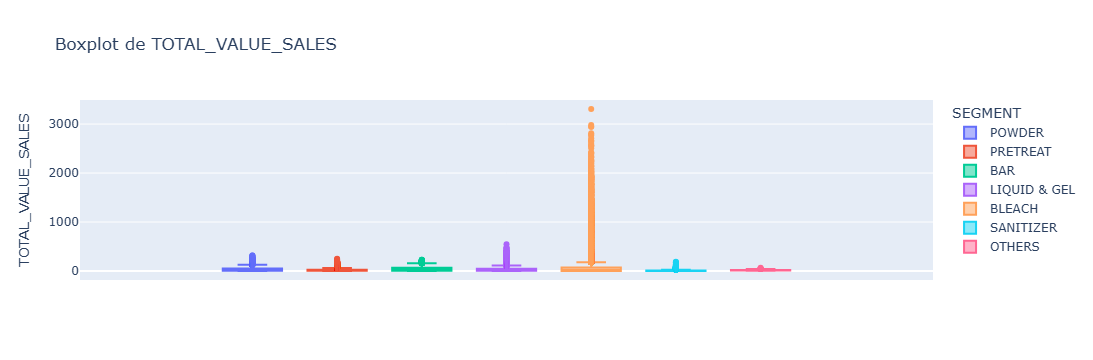

In [236]:
#Análisis por Segmento
boxplot('TOTAL_VALUE_SALES', 'SEGMENT')

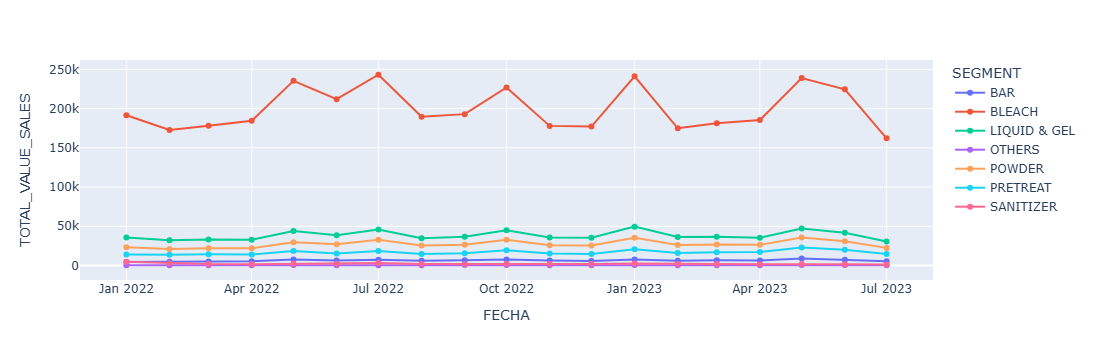

In [213]:
VentasX('SEGMENT')

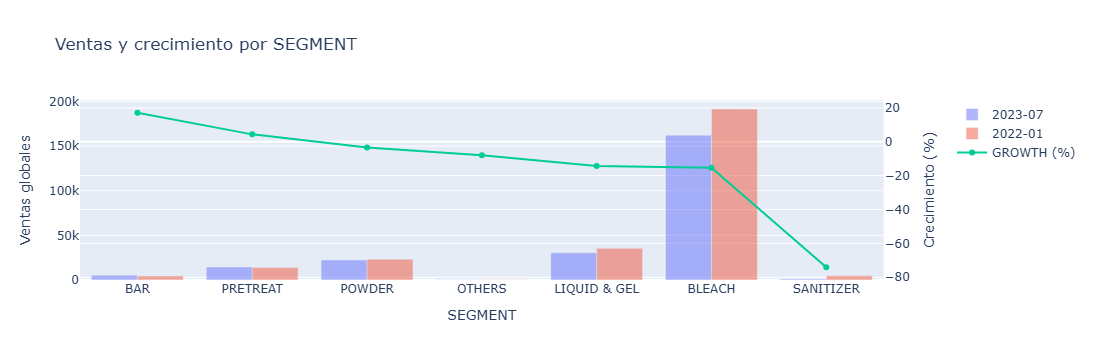

In [186]:
GrowthGraf('SEGMENT')

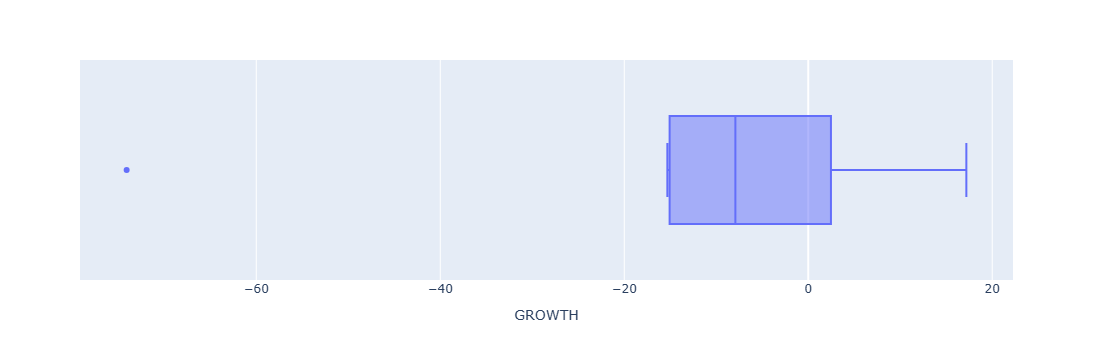

In [217]:
OutGrowth('SEGMENT')

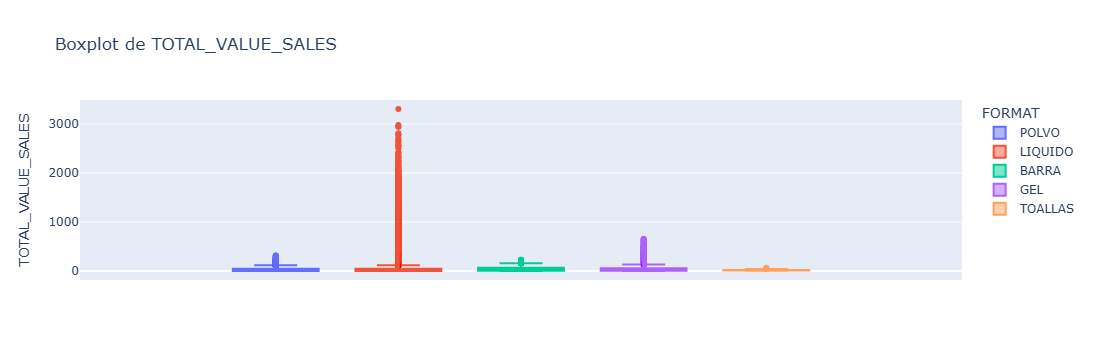

In [237]:
#Análisis por Formato
boxplot('TOTAL_VALUE_SALES', 'FORMAT')

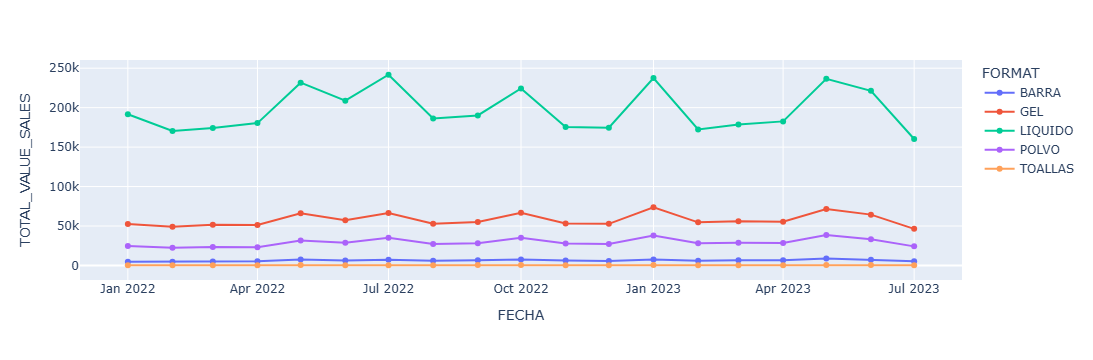

In [147]:
VentasX('FORMAT')

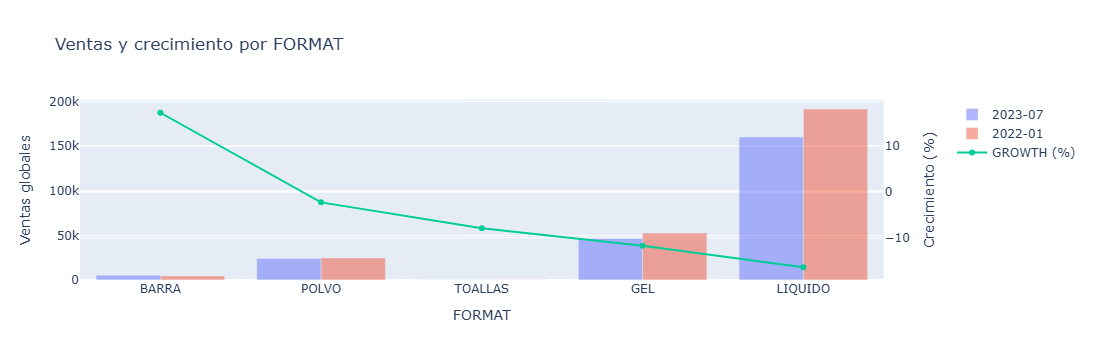

In [148]:
GrowthGraf('FORMAT')

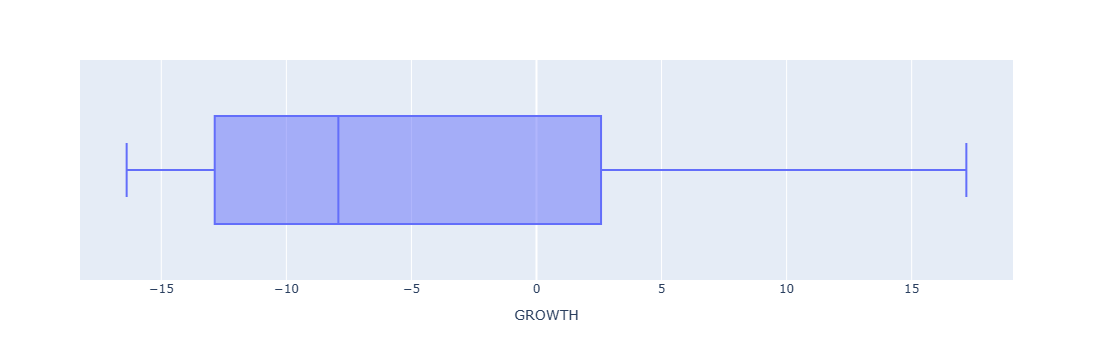

In [218]:
OutGrowth('FORMAT')

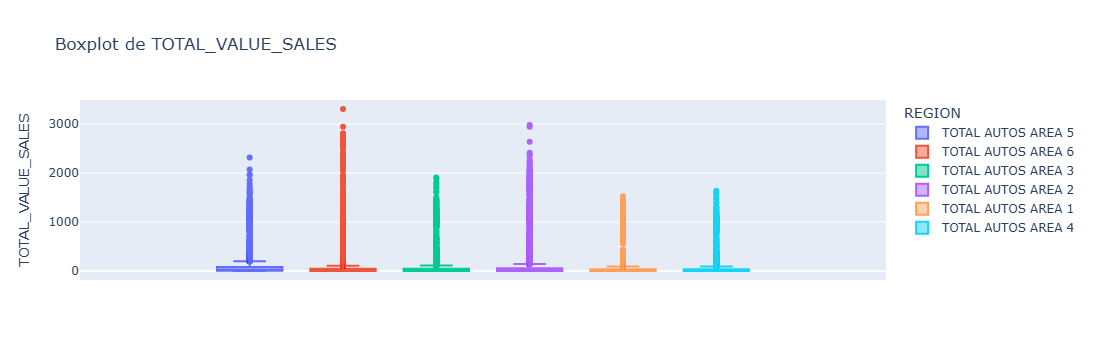

In [238]:
#Analisis por region
boxplot('TOTAL_VALUE_SALES', 'REGION')

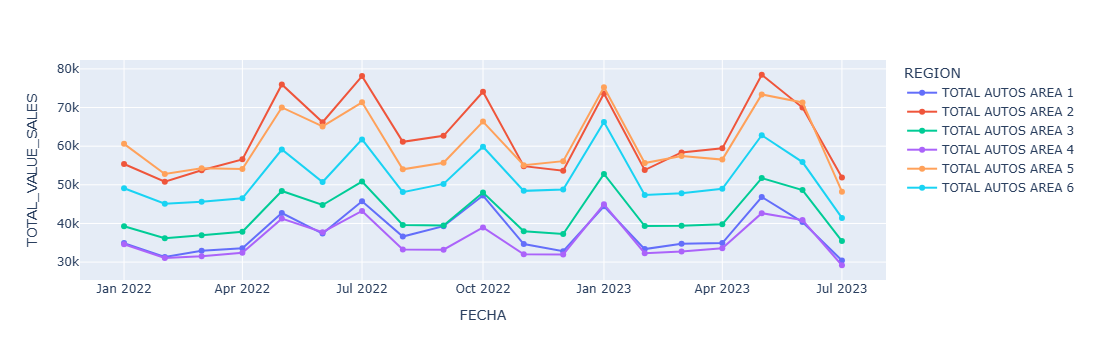

In [149]:
VentasX('REGION')

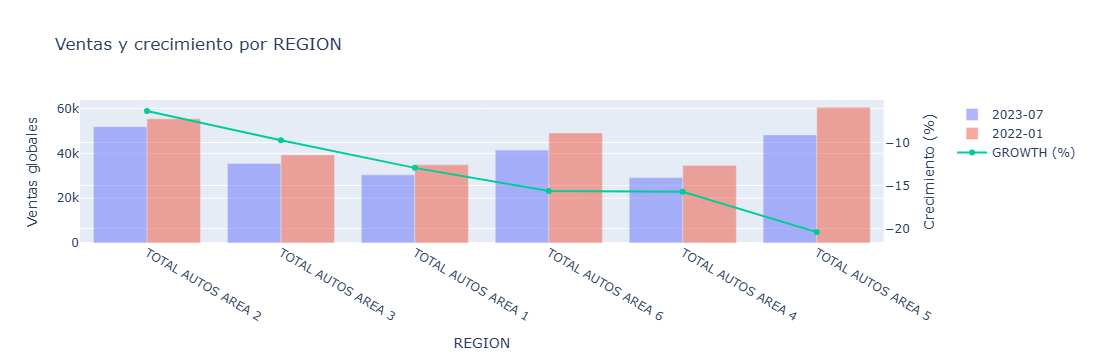

In [197]:
GrowthGraf('REGION')

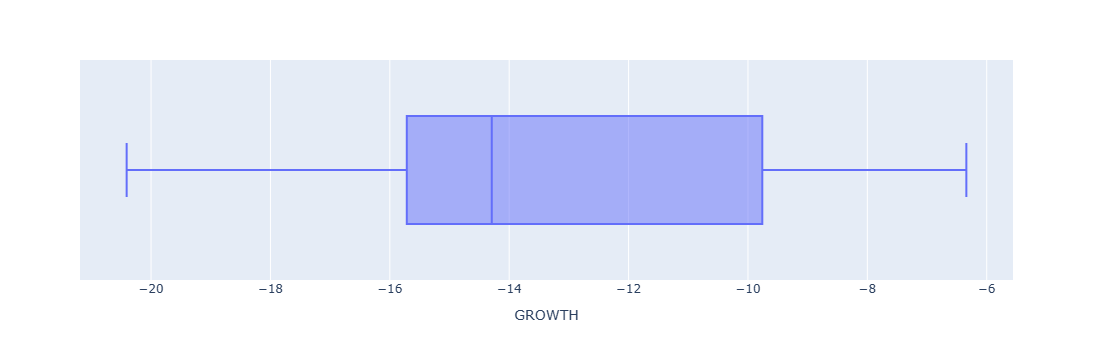

In [219]:
OutGrowth('REGION')

In [187]:
#Análisis por producto

dSalesFinal4 = dSalesFinal3.copy()
dSalesFinal4 = dSalesFinal4.groupby('ITEM_DESCRIPTION')[['SEGMENT', 'FORMAT', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].agg(
    {
        'SEGMENT': 'first',
        'FORMAT' : 'first',
        'TOTAL_UNIT_SALES': 'sum',
        'TOTAL_VALUE_SALES': 'sum'
    }
).reset_index(
    ).sort_values(by = 'TOTAL_VALUE_SALES', ascending = False)
dSalesFinal4.head(10)

,ITEM_DESCRIPTION,SEGMENT,FORMAT,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
74,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,BLEACH,LIQUIDO,14167.209,573424.820
72,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,BLEACH,LIQUIDO,24222.575,569616.894
77,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,BLEACH,LIQUIDO,23230.925,329292.282
27,BLANCATEL CONCENTRADO BOT PLAST 3750ML NAL 750...,BLEACH,LIQUIDO,7806.605,245537.612
164,CLOROX REGULAR CONCENTRADO BOTPLAST.3800ML 750...,BLEACH,LIQUIDO,5564.615,199997.395
113,CLORALEX ULTRAGEL CLORO EN GEL CONCENTRADO 950...,BLEACH,GEL,4833.536,121090.566
70,CLORALEX EL RENDIDOR BOT 1900+100ML= 2LT 75010...,BLEACH,LIQUIDO,5039.848,120749.440
114,CLORALEX ULTRAGEL CLORO GEL CONCENTRADO BOT 60...,BLEACH,GEL,7015.705,117892.195
54,CLORALEX CLORO EN GEL BOT 950ML 7501025405151,BLEACH,GEL,5484.347,99905.728
55,CLORALEX CLORO EN GEL BP 2000ML 7501025405106,BLEACH,GEL,2812.227,87555.497


In [188]:
dSalesFinal4.tail(10)

,ITEM_DESCRIPTION,SEGMENT,FORMAT,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
50,CLORALEX BAMBINO BOT PLAST 2000ML NAL 75010254...,BLEACH,LIQUIDO,0.002,0.013
91,CLORALEX GERANIO Y ALOE BOT PLAS 950 ML 750102...,BLEACH,LIQUIDO,0.001,0.012
86,CLORALEX FRESCURA CITRICA BOT PLAST 2000ML NAL...,BLEACH,LIQUIDO,0.002,0.010
3,B'CLORHADA BLANQUEADOR CONCENTRADO BOT 960 ML ...,BLEACH,LIQUIDO,0.001,0.009
25,BLANCATEL BOT.PLAST. 930 ML. NAL. 7501025402037,BLEACH,LIQUIDO,0.001,0.007
163,CLOROX REGULAR CONCENTRADO BOTPLAST.225 ML 750...,BLEACH,LIQUIDO,0.004,0.007
32,BOGAMAR CLORO BOT PLAS 980ML NAL 0616533000525,BLEACH,LIQUIDO,0.001,0.007
295,VANISH OXI ACTION CRISTAL WHITE AHORRO DEL 25%...,POWDER,POLVO,0.001,0.007
83,CLORALEX ELRENDIDORLIQBP950ML+PINOLELORIGCITRI...,BLEACH,LIQUIDO,0.001,0.004
85,CLORALEX FRESCURA CITRICA BOT PLAST 950ML NAL...,BLEACH,LIQUIDO,0.001,0.002


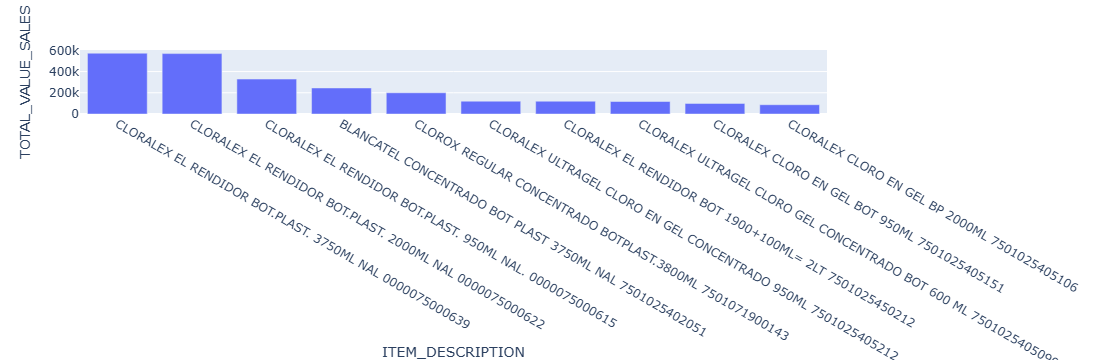

In [189]:
px.bar(
    dSalesFinal4.head(10),
    x = 'ITEM_DESCRIPTION',
    y = 'TOTAL_VALUE_SALES'
)

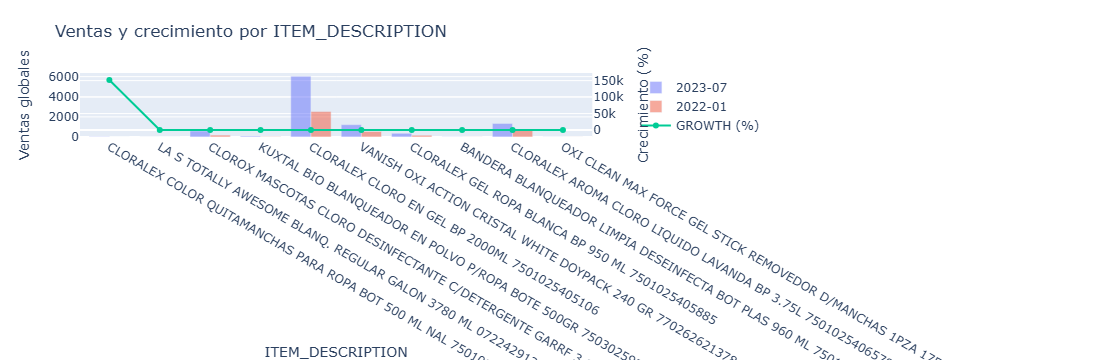

In [168]:
GrowthGraf('ITEM_DESCRIPTION')

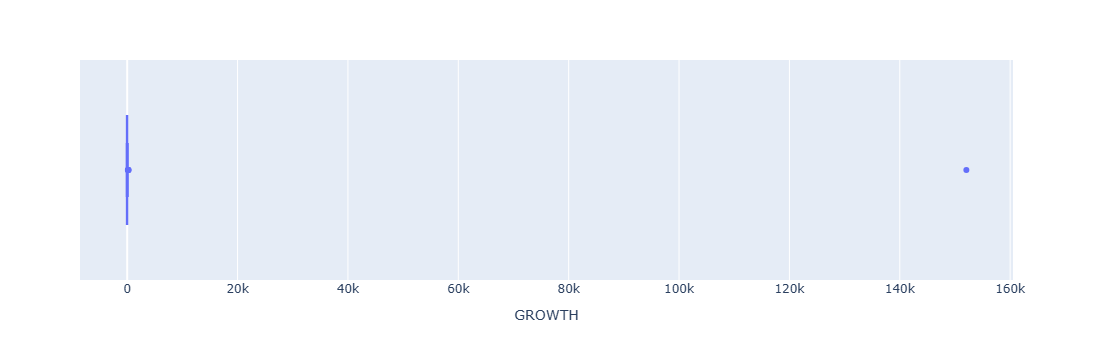

In [220]:
OutGrowth('ITEM_DESCRIPTION')

In [202]:
Growth('ITEM_DESCRIPTION')

FECHA,ITEM_DESCRIPTION,2022-01-01 00:00:00,2022-02-01 00:00:00,2022-03-01 00:00:00,2022-04-01 00:00:00,2022-05-01 00:00:00,2022-06-01 00:00:00,2022-07-01 00:00:00,2022-08-01 00:00:00,2022-09-01 00:00:00,...,2022-11-01 00:00:00,2022-12-01 00:00:00,2023-01-01 00:00:00,2023-02-01 00:00:00,2023-03-01 00:00:00,2023-04-01 00:00:00,2023-05-01 00:00:00,2023-06-01 00:00:00,2023-07-01 00:00:00,GROWTH
62,CLORALEX COLOR QUITAMANCHAS PARA ROPA BOT 500 ...,0.030,NaN,NaN,0.045,0.030,NaN,0.015,0.019,0.015,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.953,45.649,152063.333333
223,LA S TOTALLY AWESOME BLANQ. REGULAR GALON 3780...,1.061,3.295,20.323,14.763,16.358,26.016,18.824,23.889,32.192,...,22.819,27.668,9.008,1.476,1.058,14.820,27.909,17.033,3.771,255.419416
153,CLOROX MASCOTAS CLORO DESINFECTANTE C/DETERGEN...,188.791,116.813,292.919,593.279,936.015,688.688,874.762,671.411,745.081,...,805.169,870.869,1022.795,751.025,854.409,860.191,1044.016,916.213,600.100,217.864729
218,KUXTAL BIO BLANQUEADOR EN POLVO P/ROPA BOTE 50...,36.441,30.252,31.997,39.344,52.909,55.805,90.052,72.589,83.178,...,73.542,63.000,112.284,83.156,80.675,90.309,121.367,113.462,94.869,160.335885
55,CLORALEX CLORO EN GEL BP 2000ML 7501025405106,2536.056,2252.677,2224.354,2266.911,2947.928,3026.973,3025.345,2199.748,2212.069,...,4501.382,5924.657,8499.025,6944.764,7166.339,6905.585,8348.369,7849.436,6044.818,138.355068
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328,VANISH ROSA QUITAMANCHAS GEL BOT 3.8 LT PROM E...,NaN,1195.673,2551.969,2816.089,3914.196,3345.100,4082.935,3008.581,3062.834,...,3761.363,3971.906,5760.865,3990.416,3774.456,3638.966,5302.422,4535.850,3383.475,NaN
338,VANISH WHITE QUITAMANCHAS Y BLANQ.S/CLORO DOYP...,0.020,0.145,0.040,0.260,0.072,0.066,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
344,VANISHOXIACTIONGOLDCRYSTALWHITEBOT900GR+MMROSA...,2.076,1.745,2.766,1.106,1.383,0.830,0.553,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
345,VANISHOXIACTIONGOLDROSABOT150GR+MMCRYSTALWHITE...,0.309,0.262,0.414,0.166,0.207,0.124,0.083,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [190]:
#INSIGHTS:
#En total se analizaron 101,012 registros de venta entre 2022-01-09 y 2023-07-17, correspondientes a 350 articulos diferentes.
#El mes con mayores ventas fue enero de 2023 (357314.264)
#El mes con menores ventas fue julio de 2023 (236563.339)
#La tendencia general del negocio indica que se tiene un crecimiento en las ventas, aunque en los últimos meses ha tendido a la baja.
#La region con más ventas en el periodo analizado es el AREA 2 y con el menor numero el AREA 4.
#Se tiene un descenso en el crecimiento entre enero 2022 y julio 2023, siendo la menos afectada la región 2 (-6.34%) y la más afectada la 5 (-20.40%).
#El segmento más vendido en el periodo es el BLEACH, y el menor el SANITIZER.
#El segmento con mayor crecimiento es el de barra (+17.18%) y el menor el del sanitizante (-74.08%).
#El formato más vendido en el periodo es el líquido, y el menor las toallas.
#El formato con mayor crecimiento es la barra (+17.18%), y el menor, paradógicamente, el líquido (-16.38%)
#El producto más vendido durante el periodo es CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL, seguido del CLORALEX EL RENDIDOR BOT.PLAST. 2000ML y el
#CLORALEX EL RENDIDOR BOT.PLAST. 950ML.
#Los menos vendidos corresponden en primer lugar al CLORALEX FRESCURA CITRICA  BOT PLAST 950ML, CLORALEX ELRENDIDORLIQBP950ML+PINOLELORIGCITRI y 
#VANISH OXI ACTION CRISTAL WHITE AHORRO DEL 25%.
#El producto con mayor crecimiento corresponde al CLORALEX COLOR QUITAMANCHAS PARA ROPA BOT 500 ML (+152,063.3%), seguido de 
#LA S TOTALLY AWESOME BLANQ. REGULAR GALON 3780 ML (+255.41%) y CLOROX MASCOTAS CLORO DESINFECTANTE C/DETERGENTE GARRF (+217.86%)

In [ ]:
#Esto es solo para el ejercicio
dSalesFinal3.to_csv('dSalesFinal3.csv', index = False)

In [ ]:
eta5.to_csv('eta5.csv)